# 03 · Results: teams and players
This notebook uses the archetype model built in `02_model.ipynb`. It reads the saved results and turns them into
team and player analysis: a team case study, a heatmap of the 16 teams, archetype player cards and an interactive explorer.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

order = ["Floor General", "Ball-Hawk Guard", "Combo Creator", "Scoring Wing",
         "Spot-Up Shooter", "Rim Protector", "Interior Star", "Glass Cleaner"]

mix25 = pd.read_csv("data/archetype_mix_2025.csv", dtype={"player_id": str})
mix26 = pd.read_csv("data/archetype_mix_2026.csv", dtype={"player_id": str})
change = pd.read_csv("data/archetype_change.csv", dtype={"player_id": str})
zs = pd.read_csv("data/zscores_2025.csv", dtype={"player_id": str})

print(mix25.shape, mix26.shape, change.shape, zs.shape)
mix25.head(3)

(142, 19) (142, 15) (77, 35) (142, 16)


,player_url,player_id,min,player,team,position,height,Floor General,Ball-Hawk Guard,Combo Creator,Scoring Wing,Spot-Up Shooter,Rim Protector,Interior Star,Glass Cleaner,main_archetype,main_weight,pos_group,arch_group
0,https://baloncestoenvivo.feb.es/Jugador.aspx?i...,1867462,466.050000,"SANTIBAÑEZ HERRERO, INES",CLUB JOVENTUT BADALONA,SG,173.0,0.291214,0.169337,0.119099,0.000000,0.186166,0.0,0.067226,0.166957,Floor General,0.291214,guard,guard
1,https://baloncestoenvivo.feb.es/Jugador.aspx?i...,1937427,554.633333,"LAMANA LLOBERA, LAIA",CLUB JOVENTUT BADALONA,PG,170.0,0.028231,0.537968,0.000000,0.260727,0.173075,0.0,0.000000,0.000000,Ball-Hawk Guard,0.537968,guard,guard
2,https://baloncestoenvivo.feb.es/Jugador.aspx?i...,1952614,553.816667,"PIERA FLO, LAURA",CLUB JOVENTUT BADALONA,PG,173.0,0.251310,0.356437,0.000000,0.000000,0.189161,0.0,0.000000,0.203092,Ball-Hawk Guard,0.356437,guard,guard


## 1. Team case study: Valencia B.C. (2025/26)
A team's archetype mix is the minute-weighted average of its players' mixes: players who are on court longer weigh
more. Comparing it with the league average shows what a roster has in excess and what it lacks. Only players in the
sample (300+ minutes) are included, so this describes each team's main rotation.

In [3]:
weighted = mix25[order].mul(mix25["min"], axis=0)            # each weight × minutes
team_mix = weighted.groupby(mix25["team"]).sum().div(mix25.groupby("team")["min"].sum(), axis=0)
league_mix = weighted.sum() / mix25["min"].sum()

valencia = pd.DataFrame({"Valencia": team_mix.loc["VALENCIA B.C."], "League": league_mix})
valencia["difference"] = valencia["Valencia"] - valencia["League"]
print(valencia.round(3))

print("\nValencia's rotation:")
print(mix25.loc[mix25["team"] == "VALENCIA B.C.", ["player", "position", "min", "main_archetype", "main_weight"]]
           .sort_values("min", ascending=False).round(2))

                 Valencia  League  difference
Floor General       0.058   0.150      -0.092
Ball-Hawk Guard     0.126   0.103       0.023
Combo Creator       0.091   0.125      -0.035
Scoring Wing        0.176   0.145       0.031
Spot-Up Shooter     0.146   0.133       0.013
Rim Protector       0.207   0.089       0.119
Interior Star       0.180   0.171       0.009
Glass Cleaner       0.016   0.084      -0.069

Valencia's rotation:
                      player position     min   main_archetype  main_weight
73  BUENAVIDA ESTEVEZ, ELENA       SG  647.85  Spot-Up Shooter         0.37
74            FAM THIAM, AWA        C  639.80    Interior Star         0.47
72       PEREZ ARAUJO, MARIA       PF  611.25    Rim Protector         0.52
75           FIEBICH, LEONIE       SF  586.05     Scoring Wing         0.48
71  ROMERO GONZALEZ, LETICIA       PG  512.92     Scoring Wing         0.46
70   CASAS CARRERAS, QUERALT       SG  437.88  Ball-Hawk Guard         0.32
80  CARRERA QUINTANA, RAQUEL    

**Valencia's identity.** Compared with the league, Valencia's rotation has more than twice the Rim Protector share
(0.21 vs 0.09: Pérez Araujo, Carrera and Coffey), and slightly more Scoring Wing and Ball-Hawk Guard. It lacks a classic
Floor General (0.06 vs 0.15): its three point guards (Romero, Ben Abdelkader, Anderson) all profile as Scoring Wings,
so creation is shared rather than run by one organiser. It has almost no Glass Cleaner (0.02 vs 0.08): rebounding comes
from rim protectors and interior stars who do more than rebound. Eleven players reach 300 minutes and none exceeds 650,
a deep and evenly shared rotation.

## 2. Team fingerprints: all 16 teams
Each cell is a team's archetype share minus the league average: red means the roster has more of that archetype,
blue means less. Teams are sorted by their interior share (Rim Protector + Interior Star + Glass Cleaner).

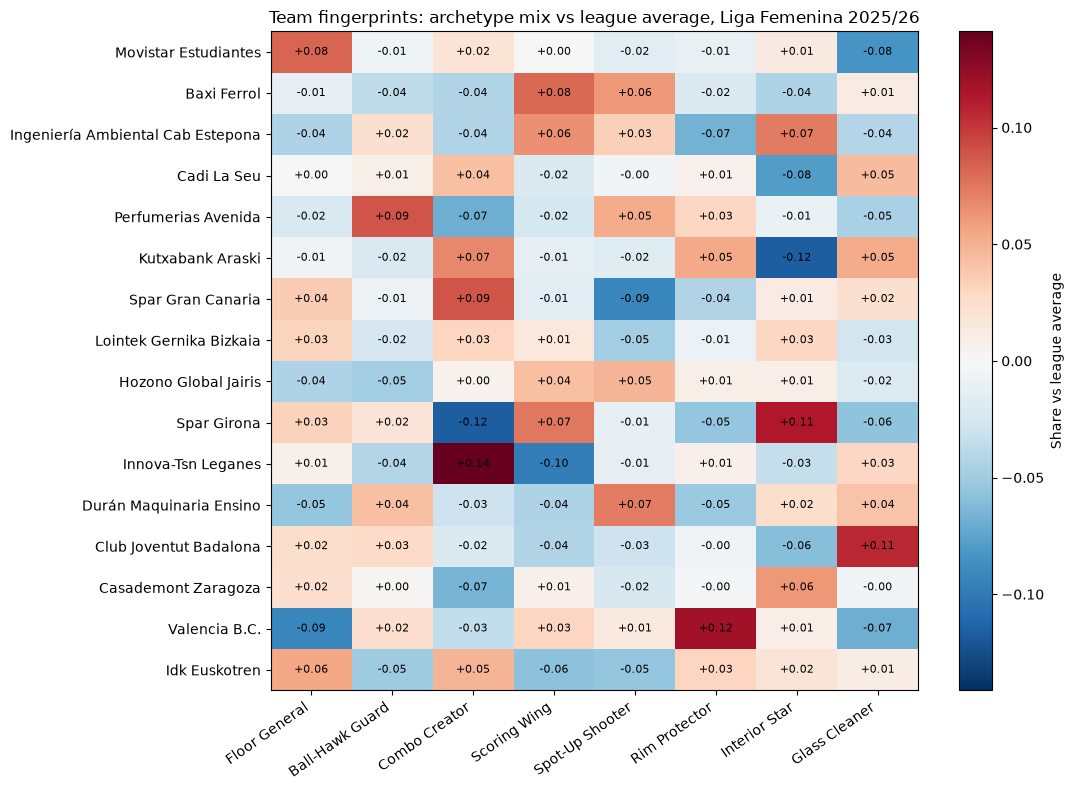

In [4]:
diff = team_mix[order] - league_mix
interior = team_mix[["Rim Protector", "Interior Star", "Glass Cleaner"]].sum(axis=1)
diff = diff.loc[interior.sort_values().index]                 # perimeter teams on top, interior teams at the bottom

vmax = diff.abs().to_numpy().max()
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(diff, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")

ax.set_xticks(range(len(order)), labels=order, rotation=35, ha="right")
ax.set_yticks(range(len(diff)), labels=diff.index.str.title())
for i in range(diff.shape[0]):
    for j in range(diff.shape[1]):
        ax.text(j, i, f"{diff.iloc[i, j]:+.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="Share vs league average")
ax.set_title("Team fingerprints: archetype mix vs league average, Liga Femenina 2025/26")
plt.tight_layout()
plt.savefig("figures/team_fingerprints.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading the fingerprints.** Every team has a distinct profile, usually driven by one or two archetypes. The largest
deviations are about ±0.12 of rotation minutes, roughly one player's worth: a team's identity often comes down to one
or two players. Examples: Leganés builds on Combo Creators (+0.14) rather than Scoring Wings (−0.10); Valencia on Rim
Protectors (+0.12) without a classic Floor General (−0.09); Girona on Interior Stars (+0.11); Joventut on Glass Cleaners
(+0.11); Araski has the league's largest gap in Interior Stars (−0.12); Avenida stands out for Ball-Hawk Guards (+0.09).
Sorting by interior share produces no clear gradient: team identities are combinations of archetypes, not positions
on a single perimeter–interior scale.

**Team composition.** The heatmap above shows differences from the league; this chart shows each rotation's absolute
composition: the share of minute-weighted archetype mix that each archetype represents. The league average is shown on
top for reference. Teams are sorted by their perimeter share (the five guard and wing archetypes).

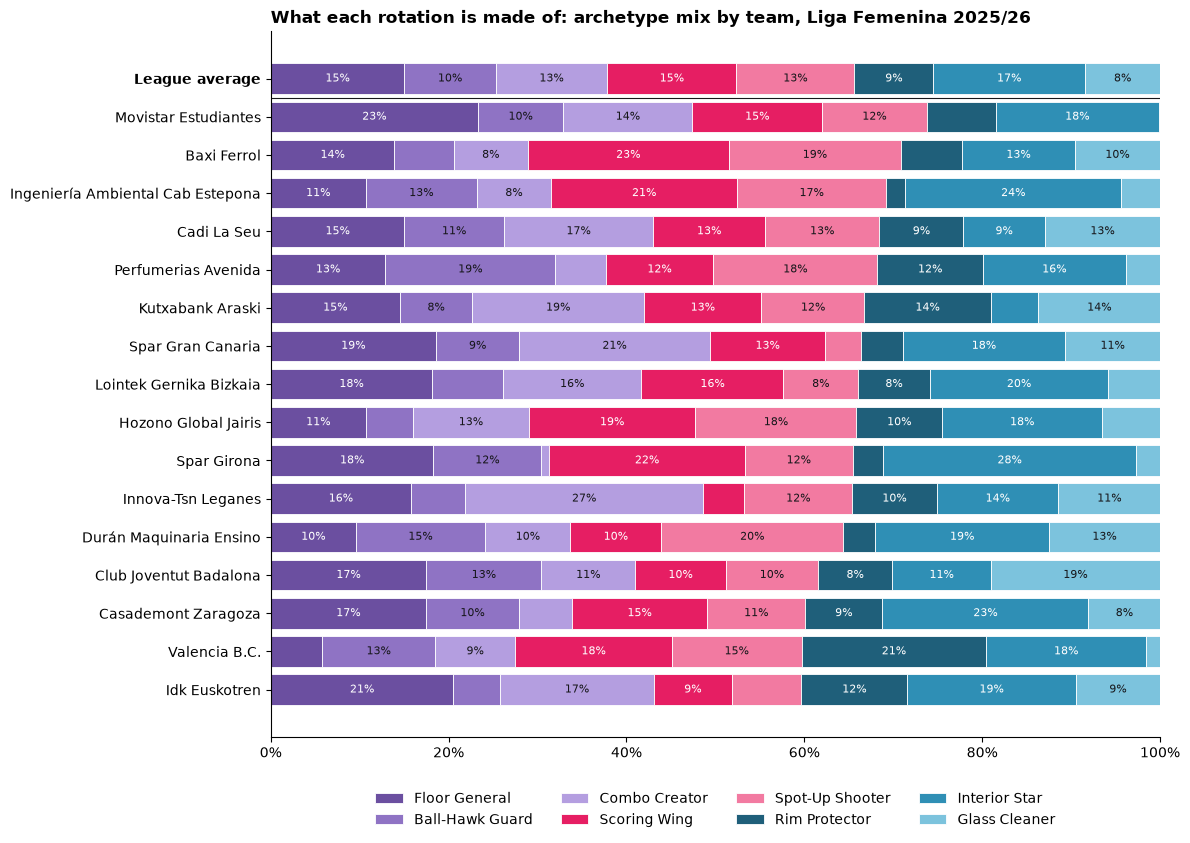

In [13]:
comp = team_mix[order].copy()
comp.index = comp.index.str.title()
perimeter = comp[["Floor General", "Ball-Hawk Guard", "Combo Creator", "Scoring Wing", "Spot-Up Shooter"]].sum(axis=1)
comp = comp.loc[perimeter.sort_values().index]                     # most interior at the bottom, most perimeter at the top
comp.loc["League average"] = league_mix[order]                      # reference bar, last row = top of the chart

fig, ax = plt.subplots(figsize=(12, 8.5))
left = np.zeros(len(comp))
for a in order:
    vals = comp[a].to_numpy()
    ax.barh(comp.index, vals, left=left, color=colors[a], label=a, edgecolor="white", linewidth=0.6)
    for k, (v, l) in enumerate(zip(vals, left)):
        if v >= 0.08:                                               # label only segments wide enough to read
            ax.text(l + v / 2, k, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if a in ["Floor General", "Scoring Wing", "Rim Protector", "Interior Star"] else "#16161a")
    left += vals

ax.get_yticklabels()[-1].set_fontweight("bold")                     # highlight the league average
ax.axhline(len(comp) - 1.5, color="#16161a", lw=0.8)                # line separating the league average
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.06), frameon=False)
ax.set_title("What each rotation is made of: archetype mix by team, Liga Femenina 2025/26", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/team_composition.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading the composition.** Every rotation contains all eight archetypes and resembles the league average more than it
differs from it. Identity lives at the margin, in one block larger than usual: Leganés 27% Combo Creator (league 13%),
Girona 28% Interior Star (17%), Estudiantes 23% Floor General (15%), Ferrol 23% Scoring Wing (15%), Valencia 21% Rim
Protector (9%), Joventut 19% Glass Cleaner (8%). Teams are sorted by perimeter share, most perimeter-oriented on top.

## 3. Archetype player cards
One card per player: the archetype mix, a percentile radar of the 15 features (percentiles within the 2025/26 sample),
and the three most similar players (cosine KNN on the standardised features). We first build one card, then loop over all players.

In [5]:
import re
from sklearn.neighbors import NearestNeighbors

feats = pd.read_csv("data/features_2025.csv", dtype={"player_id": str})
feats = feats[feats["in_sample"]].reset_index(drop=True)
feature_cols = [c for c in zs.columns if c != "player_id"]

# The three tables must be in the same row order
print((feats["player_id"] == mix25["player_id"]).all(), (zs["player_id"] == mix25["player_id"]).all())

# Percentiles within the sample (turnovers inverted: higher = better ball security)
pct = feats[feature_cols].rank(pct=True) * 100
pct["tov_pct"] = 100 - pct["tov_pct"]
pct["row"] = range(len(pct))
pct_long = pct.melt(id_vars="row", var_name="feature", value_name="percentile")

# Cosine KNN on the standardised features
knn = NearestNeighbors(n_neighbors=6, metric="cosine").fit(zs[feature_cols].to_numpy())
dist, idx = knn.kneighbors(zs[feature_cols].to_numpy())

def top3(i):
    out = []
    for d, j in zip(dist[i], idx[i]):
        if mix25.loc[j, "player_id"] != mix25.loc[i, "player_id"]:    # skip the player herself (and her other stint)
            out.append((j, 1 - d))
        if len(out) == 3:
            break
    return out

print(pct_long.shape)
pct_long.head()

True True
(2130, 3)


,row,feature,percentile
0,0,oreb_pct,59.154930
1,1,oreb_pct,28.873239
2,2,oreb_pct,41.549296
3,3,oreb_pct,34.507042
4,4,oreb_pct,88.028169


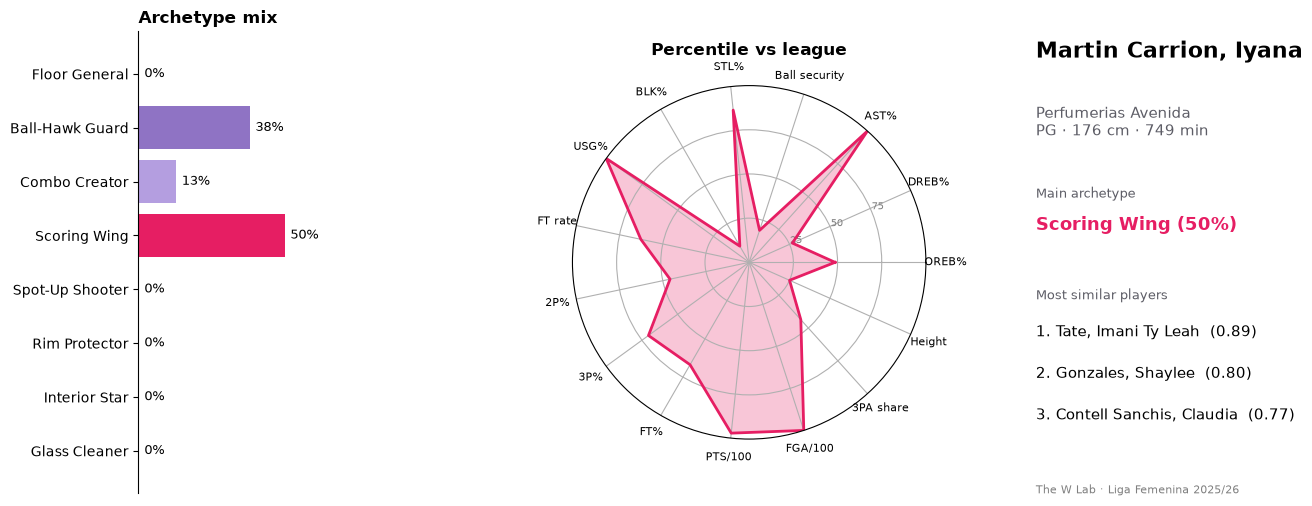

In [6]:
colors = {"Floor General": "#6b4fa0", "Ball-Hawk Guard": "#8f73c4", "Combo Creator": "#b49ee0",
          "Scoring Wing": "#e61e63", "Spot-Up Shooter": "#f27aa1",
          "Rim Protector": "#1f5f7a", "Interior Star": "#2f8fb5", "Glass Cleaner": "#7cc3dd"}

labels = {"oreb_pct": "OREB%", "dreb_pct": "DREB%", "ast_pct": "AST%", "tov_pct": "Ball security",
          "stl_pct": "STL%", "blk_pct": "BLK%", "usg_pct": "USG%", "ft_rate": "FT rate",
          "fg2_pct": "2P%", "fg3_pct": "3P%", "ft_pct": "FT%", "pts_100": "PTS/100",
          "fga_100": "FGA/100", "fg3_share": "3PA share", "height": "Height"}

def player_card(i, save=True):
    p = mix25.loc[i]
    fig = plt.figure(figsize=(15, 6))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1.2, 0.9], wspace=0.35)

    # 1. Archetype mix
    ax1 = fig.add_subplot(gs[0])
    rev = order[::-1]
    w = p[rev].astype(float)
    ax1.barh(rev, w, color=[colors[a] for a in rev])
    for k, a in enumerate(rev):
        ax1.text(w[a] + 0.02, k, f"{w[a]:.0%}", va="center", fontsize=9)
    ax1.set_xlim(0, 1.1)
    ax1.set_xticks([])
    ax1.spines[["top", "right", "bottom"]].set_visible(False)
    ax1.set_title("Archetype mix", loc="left", fontweight="bold")

    # 2. Percentile radar
    r = pct_long[pct_long["row"] == i]
    angles = np.linspace(0, 2 * np.pi, len(r), endpoint=False)
    vals = r["percentile"].to_numpy()
    ax2 = fig.add_subplot(gs[1], projection="polar")
    ax2.plot(np.append(angles, angles[0]), np.append(vals, vals[0]), color="#e61e63", lw=2)
    ax2.fill(angles, vals, color="#e61e63", alpha=0.25)
    ax2.set_xticks(angles, labels=[labels[f] for f in r["feature"]], fontsize=8)
    ax2.set_ylim(0, 100)
    ax2.set_yticks([25, 50, 75], labels=["25", "50", "75"], fontsize=7, color="grey")
    ax2.set_title("Percentile vs league", fontweight="bold", pad=22)

    # 3. Player sheet + most similar players
    ax3 = fig.add_subplot(gs[2])
    ax3.axis("off")
    ax3.text(0, 0.98, p["player"].title(), fontsize=16, fontweight="bold", va="top", wrap=True)
    ax3.text(0, 0.84, f"{p['team'].title()}\n{p['position']} · {feats.loc[i, 'height']:.0f} cm · {p['min']:.0f} min",
             fontsize=10.5, va="top", color="#5d5d66")
    ax3.text(0, 0.64, "Main archetype", fontsize=9, color="#5d5d66")
    ax3.text(0, 0.57, f"{p['main_archetype']} ({p['main_weight']:.0%})", fontsize=13,
             fontweight="bold", color=colors[p["main_archetype"]])
    ax3.text(0, 0.42, "Most similar players", fontsize=9, color="#5d5d66")
    for k, (j, s) in enumerate(top3(i)):
        ax3.text(0, 0.34 - k * 0.09, f"{k+1}. {mix25.loc[j, 'player'].title()}  ({s:.2f})", fontsize=10.5)
    ax3.text(0, 0.0, "The W Lab · Liga Femenina 2025/26", fontsize=8, color="grey")

    if save:
        name = re.sub(r"[^a-z0-9]+", "_", f"{p['player']} {p['team']}".lower()).strip("_")
        fig.savefig(f"figures/player_cards/{name}.png", dpi=150, bbox_inches="tight")
        plt.close(fig)
    else:
        plt.show()

i = mix25.index[mix25["player"].str.contains("IYANA")][0]
player_card(i, save=False)

**Card design, version 2.** The first card works but the radar follows the column order, so its shape is hard to read.
Version 2 groups the radar axes by theme (scoring, creation, defence, rebounding, size), colours the labels by group,
starts at the top, shows names as "First Last", adds the team of each similar player and avoids listing the same
player twice (players with two stints).

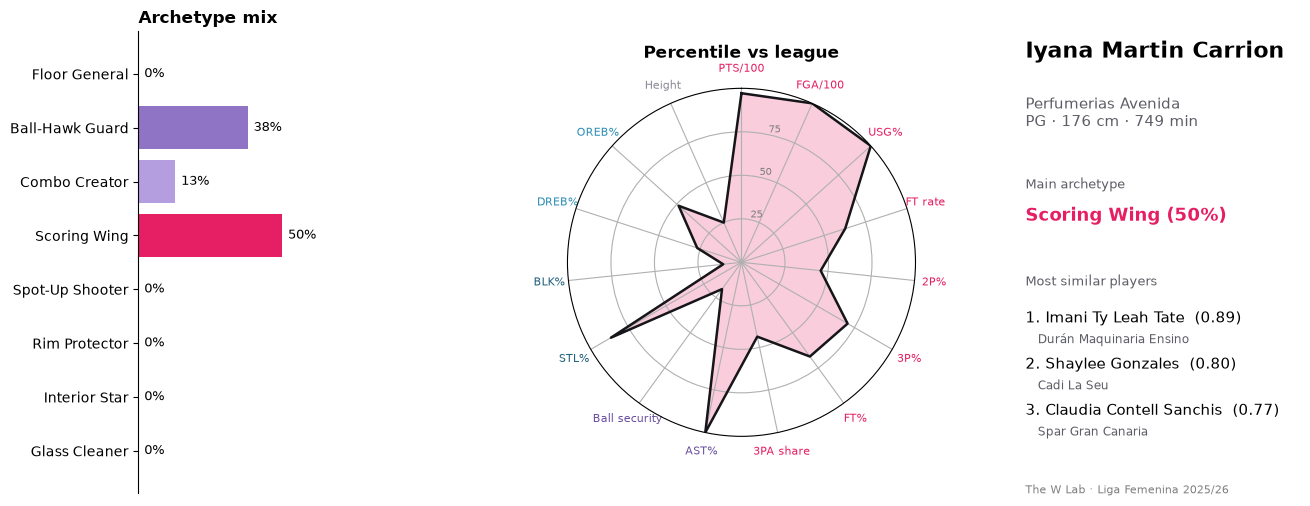

In [7]:
radar_groups = {"Scoring": ["pts_100", "fga_100", "usg_pct", "ft_rate", "fg2_pct", "fg3_pct", "ft_pct", "fg3_share"],
                "Creation": ["ast_pct", "tov_pct"],
                "Defence": ["stl_pct", "blk_pct"],
                "Rebounding": ["dreb_pct", "oreb_pct"],
                "Size": ["height"]}
group_color = {"Scoring": "#e61e63", "Creation": "#6b4fa0", "Defence": "#1f5f7a", "Rebounding": "#2f8fb5", "Size": "#8d8a99"}
radar_order = [f for g in radar_groups.values() for f in g]
feat_color = {f: group_color[g] for g, fs in radar_groups.items() for f in fs}

def nice(name):
    if ", " in name:
        last, first = name.split(", ", 1)
        name = f"{first} {last}"
    return name.title()

knn = NearestNeighbors(n_neighbors=8, metric="cosine").fit(zs[feature_cols].to_numpy())
dist, idx = knn.kneighbors(zs[feature_cols].to_numpy())

def top3(i):
    out, seen = [], {mix25.loc[i, "player_id"]}
    for d, j in zip(dist[i], idx[i]):
        pid = mix25.loc[j, "player_id"]
        if pid not in seen:                      # skip the player herself and repeated stints
            out.append((j, 1 - d))
            seen.add(pid)
        if len(out) == 3:
            break
    return out

def player_card(i, save=True):
    p = mix25.loc[i]
    fig = plt.figure(figsize=(15, 6))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1.2, 0.95], wspace=0.35)

    # 1. Archetype mix
    ax1 = fig.add_subplot(gs[0])
    rev = order[::-1]
    w = p[rev].astype(float)
    ax1.barh(rev, w, color=[colors[a] for a in rev])
    for k, a in enumerate(rev):
        ax1.text(w[a] + 0.02, k, f"{w[a]:.0%}", va="center", fontsize=9)
    ax1.set_xlim(0, 1.1)
    ax1.set_xticks([])
    ax1.spines[["top", "right", "bottom"]].set_visible(False)
    ax1.set_title("Archetype mix", loc="left", fontweight="bold")

    # 2. Percentile radar, grouped by theme
    r = pct_long[pct_long["row"] == i].set_index("feature").loc[radar_order, "percentile"]
    angles = np.linspace(0, 2 * np.pi, len(r), endpoint=False)
    vals = r.to_numpy()
    ax2 = fig.add_subplot(gs[1], projection="polar")
    ax2.set_theta_offset(np.pi / 2)              # start at the top
    ax2.set_theta_direction(-1)                  # clockwise
    ax2.plot(np.append(angles, angles[0]), np.append(vals, vals[0]), color="#16161a", lw=1.8)
    ax2.fill(angles, vals, color="#e61e63", alpha=0.22)
    ax2.set_xticks(angles, labels=[labels[f] for f in radar_order], fontsize=8)
    for lab, f in zip(ax2.get_xticklabels(), radar_order):
        lab.set_color(feat_color[f])
    ax2.set_ylim(0, 100)
    ax2.set_yticks([25, 50, 75], labels=["25", "50", "75"], fontsize=7, color="grey")
    ax2.set_rlabel_position(np.degrees(angles[1] / 2))   # numbers between the first two axes
    ax2.set_title("Percentile vs league", fontweight="bold", pad=22)

    # 3. Player sheet + most similar players
    ax3 = fig.add_subplot(gs[2])
    ax3.axis("off")
    ax3.text(0, 0.98, nice(p["player"]), fontsize=16, fontweight="bold", va="top")
    ax3.text(0, 0.86, f"{p['team'].title()}\n{p['position']} · {feats.loc[i, 'height']:.0f} cm · {p['min']:.0f} min",
             fontsize=10.5, va="top", color="#5d5d66")
    ax3.text(0, 0.66, "Main archetype", fontsize=9, color="#5d5d66")
    ax3.text(0, 0.59, f"{p['main_archetype']} ({p['main_weight']:.0%})", fontsize=13,
             fontweight="bold", color=colors[p["main_archetype"]])
    ax3.text(0, 0.45, "Most similar players", fontsize=9, color="#5d5d66")
    for k, (j, s) in enumerate(top3(i)):
        ax3.text(0, 0.37 - k * 0.1, f"{k+1}. {nice(mix25.loc[j, 'player'])}  ({s:.2f})", fontsize=10.5)
        ax3.text(0.045, 0.325 - k * 0.1, mix25.loc[j, "team"].title(), fontsize=8.5, color="#5d5d66")
    ax3.text(0, 0.0, "The W Lab · Liga Femenina 2025/26", fontsize=8, color="grey")

    if save:
        name = re.sub(r"[^a-z0-9]+", "_", f"{p['player']} {p['team']}".lower()).strip("_")
        fig.savefig(f"figures/player_cards/{name}.png", dpi=150, bbox_inches="tight")
        plt.close(fig)
    else:
        plt.show()

player_card(i, save=False)

Version 2 is used for all players. A colour legend for the radar groups and a square, dark-background layout will be
added for the social-media version.

In [8]:
import os
os.makedirs("figures/player_cards", exist_ok=True)

for i in mix25.index:
    player_card(i)                                   # save=True by default: writes the PNG and closes the figure

print(len(os.listdir("figures/player_cards")), "cards saved")

142 cards saved


## 4. Interactive league map (PCA + Plotly)
Each player lives in a 15-dimensional feature space. PCA finds the two directions that keep the most variation and
projects every player onto them, so similar players end up close together. We first read what the two axes mean
(the loadings), then build an interactive map coloured by main archetype.

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=0)
coords = pca.fit_transform(zs[feature_cols].to_numpy())
print("Variance explained:", pca.explained_variance_ratio_.round(3), "| total", pca.explained_variance_ratio_.sum().round(3))

loadings = pd.DataFrame(pca.components_.T, index=[labels[f] for f in feature_cols], columns=["PC1", "PC2"])
print("\nPC1, strongest loadings:")
print(loadings["PC1"].sort_values().round(2).iloc[[0, 1, 2, -3, -2, -1]])
print("\nPC2, strongest loadings:")
print(loadings["PC2"].sort_values().round(2).iloc[[0, 1, 2, -3, -2, -1]])

Variance explained: [0.299 0.172] | total 0.472

PC1, strongest loadings:
3PA share   -0.31
AST%        -0.25
STL%        -0.13
PTS/100      0.34
Height       0.36
OREB%        0.38
Name: PC1, dtype: float64

PC2, strongest loadings:
Ball security   -0.28
OREB%           -0.23
BLK%            -0.20
PTS/100          0.40
USG%             0.41
FGA/100          0.49
Name: PC2, dtype: float64


**Reading the axes.** PC1 (30% of the variation) runs from the perimeter (3PA share, AST%, STL%) to the paint (OREB%,
height, PTS/100). PC2 (17%) runs from low-usage role players (OREB%, BLK%, higher turnover rate) to go-to scorers
(FGA/100, USG%, PTS/100). Note: in the loadings above, "Ball security" is the raw TOV% (higher = more turnovers); the
inversion was applied only to the radar percentiles. Together the two axes keep 47% of the variation, against 69.5%
for the eight archetypes, so the map is a guide for exploring, not a replacement for the model.

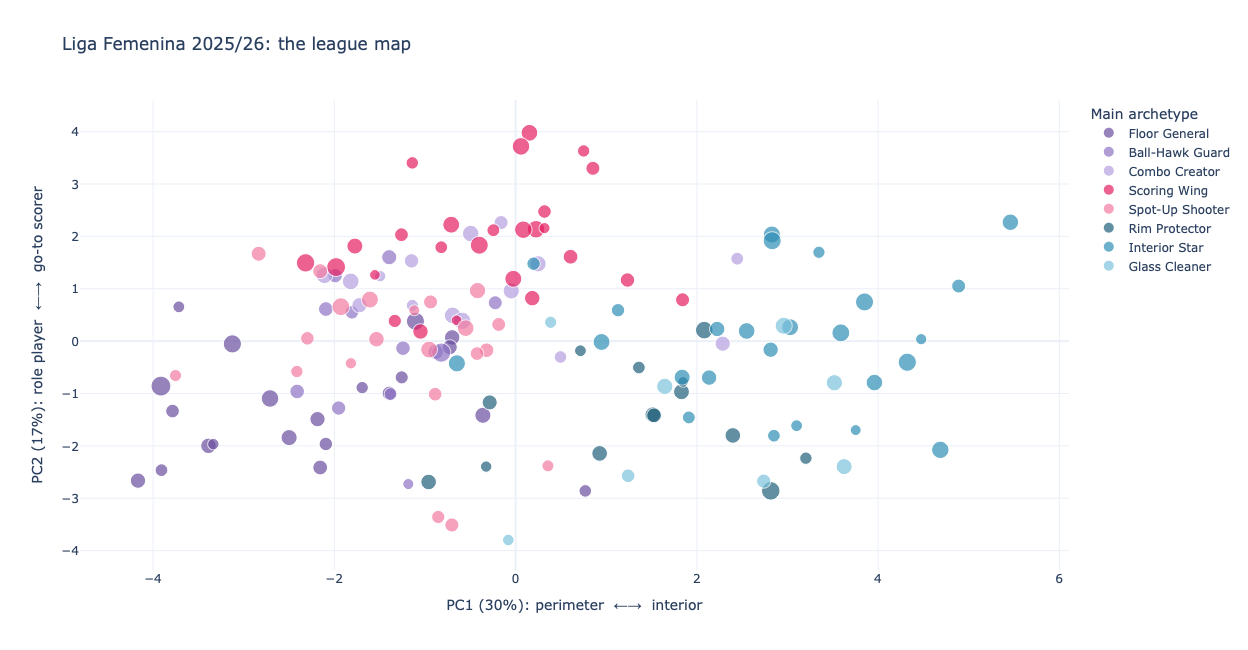

In [10]:
import plotly.express as px

mapdf = mix25[["team", "position", "min", "main_archetype"]].copy()
mapdf["name"] = mix25["player"].map(nice)
mapdf["team_name"] = mix25["team"].str.title()
mapdf["PC1"], mapdf["PC2"] = coords[:, 0], coords[:, 1]
mapdf["mix"] = mix25[order].apply(
    lambda r: " · ".join(f"{a} {w:.0%}" for a, w in r.sort_values(ascending=False).head(2).items()), axis=1)

fig = px.scatter(mapdf, x="PC1", y="PC2", color="main_archetype",
                 color_discrete_map=colors, category_orders={"main_archetype": order},
                 size="min", size_max=14, hover_name="name",
                 hover_data={"team_name": True, "position": True, "mix": True, "min": ":.0f",
                             "PC1": False, "PC2": False, "main_archetype": False},
                 labels={"PC1": "PC1 (30%): perimeter  ←→  interior",
                         "PC2": "PC2 (17%): role player  ←→  go-to scorer",
                         "main_archetype": "Main archetype", "team_name": "Team",
                         "position": "Position", "mix": "Top archetypes", "min": "Minutes"},
                 title="Liga Femenina 2025/26: the league map")
fig.update_layout(template="plotly_white", width=950, height=650)

fig.write_html("figures/plotly/league_map.html", include_plotlyjs="cdn")
fig.show()

**Adding 2026/27.** The 2026/27 players are standardised with the 2025/26 scaler and projected onto the same two PCA
axes: nothing is refitted. The scaler is rebuilt here from the same 142 players (a StandardScaler only stores means and
standard deviations) and checked against the saved z-scores. A slider switches seasons, and players present in both
seasons move across the map. Point size is relative within each season (2026/27 has only 7 rounds), and players with
two stints keep their longest one. The 2026/27 positions carry the early-season noise measured in 02_model.

Same scaler as 02: True
Aligned with mix26: True
season
2026/27 (rounds 1-7)    142
2025/26                 141
Name: count, dtype: int64


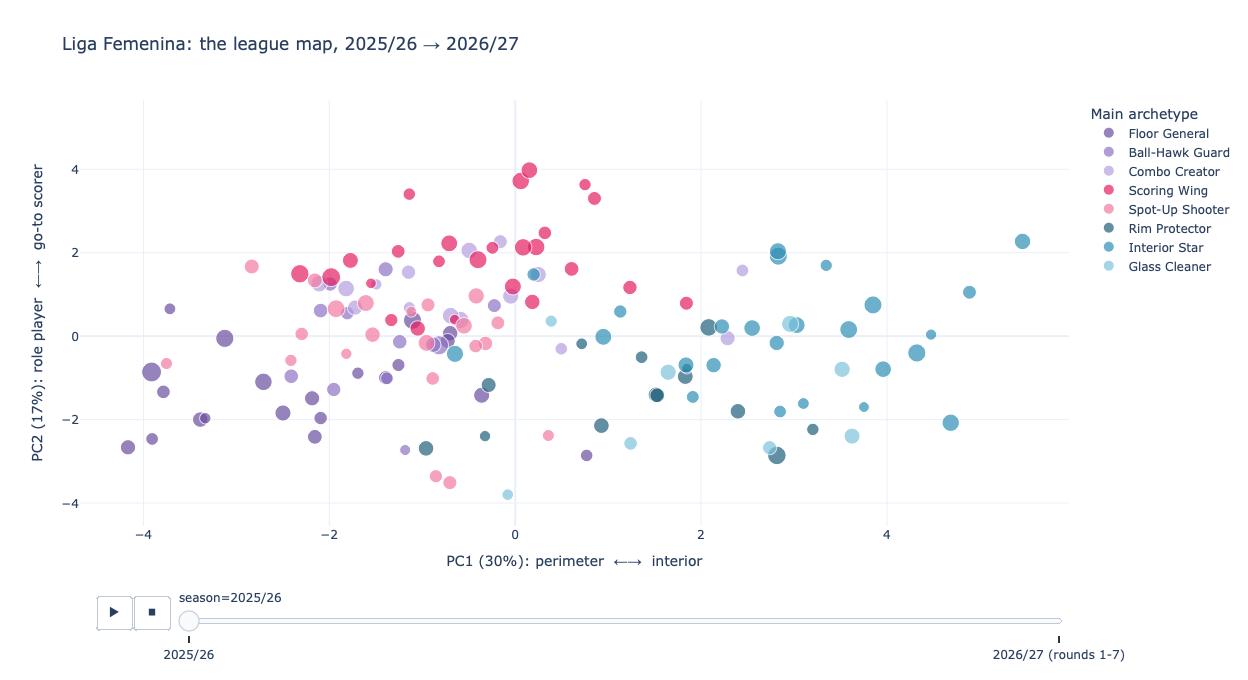

In [11]:
from sklearn.preprocessing import StandardScaler

# Rebuild the 2025/26 scaler and check it matches 02_model
scaler = StandardScaler().fit(feats[feature_cols].to_numpy())
print("Same scaler as 02:", np.allclose(scaler.transform(feats[feature_cols].to_numpy()), zs[feature_cols].to_numpy()))

# 2026/27 features, same rows as mix26
feats26 = pd.read_csv("data/features_2026.csv", dtype={"player_id": str})
feats26 = feats26[feats26["in_sample"]].reset_index(drop=True)
print("Aligned with mix26:", (feats26["player_id"] == mix26["player_id"]).all())
coords26 = pca.transform(scaler.transform(feats26[feature_cols].to_numpy()))

def map_table(mix, xy, season):
    d = mix[["player_id", "position", "min", "main_archetype"]].copy()
    d["name"] = mix["player"].map(nice)
    d["team_name"] = mix["team"].str.title()
    d["PC1"], d["PC2"] = xy[:, 0], xy[:, 1]
    d["mix"] = mix[order].apply(
        lambda r: " · ".join(f"{a} {w:.0%}" for a, w in r.sort_values(ascending=False).head(2).items()), axis=1)
    d["season"] = season
    d = d.sort_values("min", ascending=False).drop_duplicates("player_id")   # one point per player
    d["size"] = d["min"] / d["min"].max()                                    # size relative within the season
    return d

seasons = pd.concat([map_table(mix25, coords, "2025/26"),
                     map_table(mix26, coords26, "2026/27 (rounds 1-7)")], ignore_index=True)
print(seasons["season"].value_counts())

fig = px.scatter(seasons, x="PC1", y="PC2", color="main_archetype",
                 color_discrete_map=colors, category_orders={"main_archetype": order},
                 size="size", size_max=14, hover_name="name",
                 animation_frame="season", animation_group="player_id",
                 hover_data={"team_name": True, "position": True, "mix": True, "min": ":.0f",
                             "PC1": False, "PC2": False, "main_archetype": False, "size": False, "season": False},
                 labels={"PC1": "PC1 (30%): perimeter  ←→  interior",
                         "PC2": "PC2 (17%): role player  ←→  go-to scorer",
                         "main_archetype": "Main archetype", "team_name": "Team",
                         "position": "Position", "mix": "Top archetypes", "min": "Minutes"},
                 range_x=[seasons["PC1"].min() - 0.5, seasons["PC1"].max() + 0.5],
                 range_y=[seasons["PC2"].min() - 0.5, seasons["PC2"].max() + 0.5],
                 title="Liga Femenina: the league map, 2025/26 → 2026/27")
fig.update_layout(template="plotly_white", width=950, height=680)

fig.write_html("figures/plotly/league_map_seasons.html", include_plotlyjs="cdn")
fig.show()

In [12]:
seasons.groupby("season")[["PC1", "PC2"]].std().round(2)

,PC1,PC2
season,,
2025/26,2.13,1.61
2026/27 (rounds 1-7),2.05,1.74


**Reading the 2026/27 map.** Players the model has never seen fall in the expected regions: perimeter archetypes on
the left, interior ones on the right, scorers at the top. A few 2026/27 players sit at more extreme positions on PC2
(usage and scoring), but overall the spread is similar: the standard deviation on PC2 is about 8% larger than in
2025/26 (1.74 vs 1.61) and slightly smaller on PC1 (2.05 vs 2.13). Shrinkage and the 70-minute filter already limit
the most extreme early-season values, so the visual impression of a wider cloud is driven by a handful of players.

## 5. What the eight archetypes look like
Each archetype is an extreme profile in the 15 standardised features. We load the final archetype profiles and draw them
as a heatmap: red means the archetype is above the league average on that feature, blue means below.

In [14]:
profiles = pd.read_csv("data/archetype_profiles.csv", index_col=0)
print(profiles.shape)
profiles.round(2)

(8, 15)


,oreb_pct,dreb_pct,ast_pct,tov_pct,stl_pct,blk_pct,usg_pct,ft_rate,fg2_pct,fg3_pct,ft_pct,pts_100,fga_100,fg3_share,height
Combo Creator,3.80,13.76,22.29,8.78,1.46,0.19,24.80,0.21,0.39,0.27,0.73,20.73,23.72,0.35,178.16
Interior Star,13.78,22.29,6.15,15.55,1.74,1.15,23.78,0.43,0.56,0.34,0.80,29.08,19.34,0.12,192.93
Glass Cleaner,10.94,18.95,7.77,18.07,1.47,1.59,22.00,0.53,0.52,0.32,0.51,21.23,16.35,0.05,192.56
Scoring Wing,1.37,10.34,17.38,13.08,1.74,0.62,25.05,0.16,0.47,0.39,0.79,28.05,22.50,0.60,180.00
Rim Protector,6.97,22.06,9.52,17.69,1.52,3.84,18.46,0.18,0.47,0.33,0.73,17.72,15.76,0.29,190.10
Floor General,2.44,10.14,26.01,30.78,2.23,0.26,14.51,0.32,0.42,0.30,0.77,10.28,10.05,0.44,174.82
Spot-Up Shooter,2.15,7.14,6.45,7.42,2.08,0.05,9.49,0.08,0.42,0.35,0.73,9.94,9.74,0.75,178.66
Ball-Hawk Guard,4.59,10.37,26.25,25.06,6.13,0.20,24.57,0.33,0.46,0.25,0.74,19.24,18.58,0.37,169.83


In [15]:
prof = profiles.loc[order, feature_cols]                                   # rows in our archetype order
prof_z = pd.DataFrame(scaler.transform(prof.to_numpy()), index=order, columns=feature_cols)

recon = mix25[order].to_numpy() @ prof_z.to_numpy()                        # each player = her weights × archetypes
Zp = zs[feature_cols].to_numpy()
print("Explained variation:", round(1 - ((Zp - recon) ** 2).sum() / ((Zp - Zp.mean(axis=0)) ** 2).sum(), 3))

Explained variation: 0.695


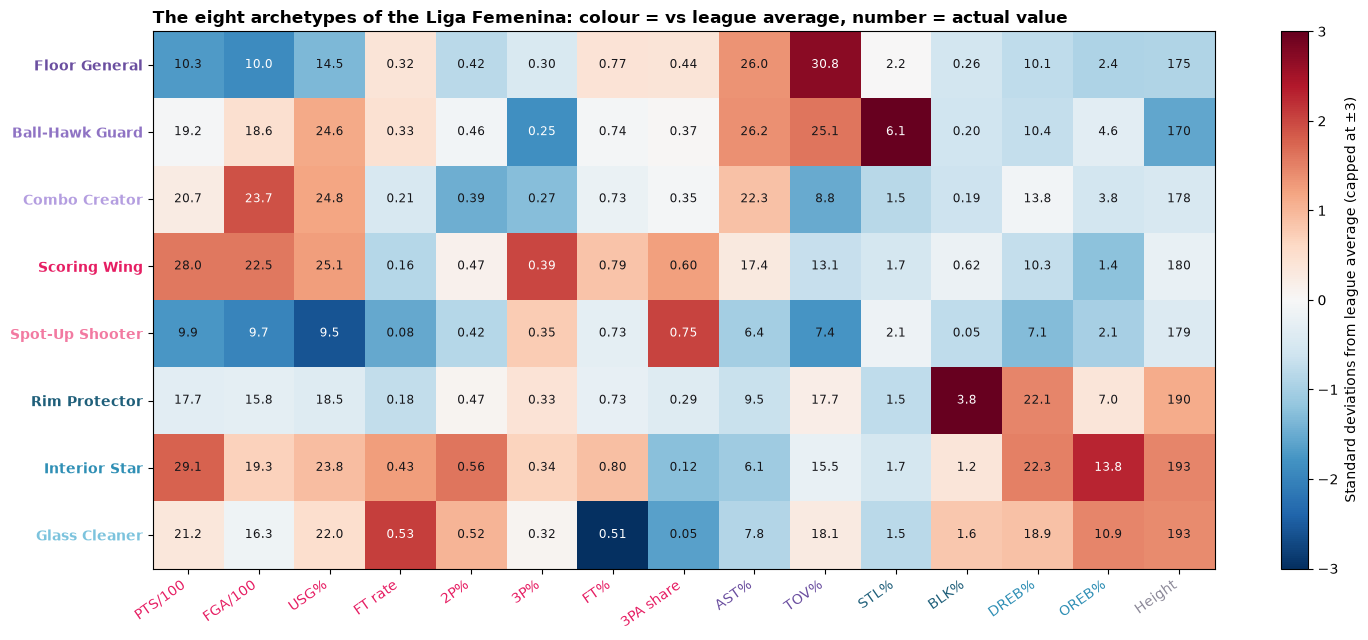

In [16]:
lab = {**labels, "tov_pct": "TOV%"}                                        # raw turnover rate here, not inverted
cols = radar_order                                                         # same thematic order as the radar
Zh = prof_z[cols]

fig, ax = plt.subplots(figsize=(15, 6.5))
im = ax.imshow(Zh, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(len(cols)), labels=[lab[c] for c in cols], rotation=35, ha="right")
for t, c in zip(ax.get_xticklabels(), cols):
    t.set_color(feat_color[c])
ax.set_yticks(range(len(order)), labels=order)
for t, a in zip(ax.get_yticklabels(), order):
    t.set_color(colors[a]); t.set_fontweight("bold")

for i, a in enumerate(order):
    for j, c in enumerate(cols):
        v = prof.loc[a, c]
        txt = f"{v:.0f}" if c == "height" else (f"{v:.2f}" if abs(v) < 1 else f"{v:.1f}")
        ax.text(j, i, txt, ha="center", va="center", fontsize=8.5,
                color="white" if abs(Zh.iloc[i, j]) > 1.8 else "#16161a")

fig.colorbar(im, ax=ax, label="Standard deviations from league average (capped at ±3)")
ax.set_title("The eight archetypes of the Liga Femenina: colour = vs league average, number = actual value",
             loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/archetype_profiles.png", dpi=200, bbox_inches="tight")
plt.show()

**Archetype radars.** The bar version varies its stats from panel to panel, which makes comparison hard. Here each
archetype gets the same radar as the player cards: the same 15 axes, the same order, percentiles within the 2025/26
sample (turnovers inverted as ball security). Comparing archetypes becomes comparing shapes, and a player card can be read
against them. Under each radar: a one-line summary and the purest player (highest weight on that archetype).

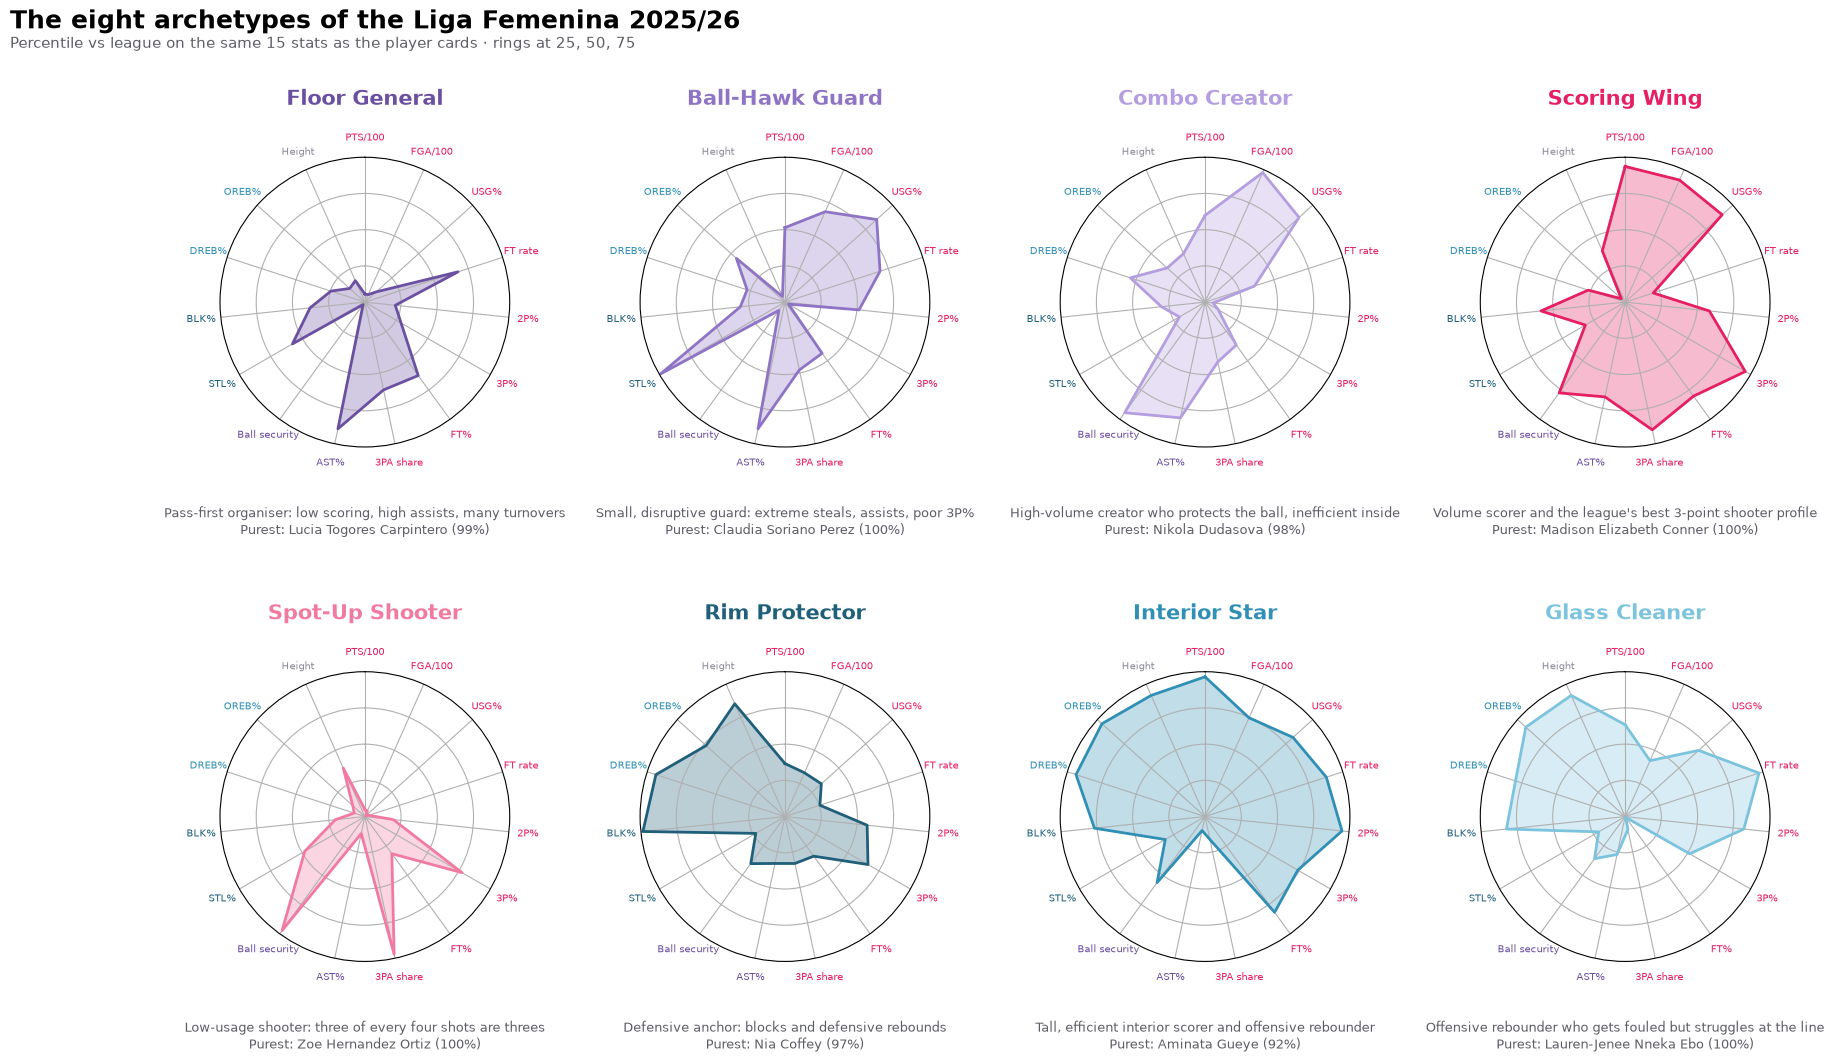

In [19]:
# Percentile of each archetype's value within the 142 players (same scale as the player cards)
arch_pct = pd.DataFrame({c: [(feats[c] < prof.loc[a, c]).mean() * 100 for a in order] for c in feature_cols},
                        index=order)
arch_pct["tov_pct"] = 100 - arch_pct["tov_pct"]                     # inverted: higher = better ball security

purest = {a: mix25.loc[mix25[a].idxmax()] for a in order}             # player with the highest weight

angles = np.linspace(0, 2 * np.pi, len(radar_order), endpoint=False)
fig, axes = plt.subplots(2, 4, figsize=(20, 11), subplot_kw={"projection": "polar"})
for ax, a in zip(axes.flat, order):
    vals = arch_pct.loc[a, radar_order].to_numpy()
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.plot(np.append(angles, angles[0]), np.append(vals, vals[0]), color=colors[a], lw=2)
    ax.fill(angles, vals, color=colors[a], alpha=0.3)
    ax.set_xticks(angles, labels=[labels[f] for f in radar_order], fontsize=7.5)
    for t, f in zip(ax.get_xticklabels(), radar_order):
        t.set_color(feat_color[f])
    ax.set_ylim(0, 100)
    ax.set_yticks([25, 50, 75], labels=[])
    ax.set_title(a, fontweight="bold", fontsize=15, color=colors[a], pad=20)
    p = purest[a]
    ax.text(0.5, -0.2, f"{tagline[a]}\nPurest: {nice(p['player'])} ({p[a]:.0%})",
            transform=ax.transAxes, ha="center", va="top", fontsize=9.5, color="#5d5d66")

fig.suptitle("The eight archetypes of the Liga Femenina 2025/26", x=0.02, ha="left", fontweight="bold", fontsize=18)
fig.text(0.02, 0.945, "Percentile vs league on the same 15 stats as the player cards · rings at 25, 50, 75",
         fontsize=11, color="#5d5d66")
fig.subplots_adjust(hspace=0.6, wspace=0.45, top=0.86, bottom=0.1)
plt.savefig("figures/archetype_radars.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Comparison with the original paper (men's European leagues)
"Scouting Anyone" (MIT Sloan SSAC 2026) fits Archetypal Analysis with the same 15 features, the same 300-minute filter,
z-scores, player-season-team units and K = 8, on seven men's domestic leagues (including the Spanish ACB), 2014–2025.
Because the recipe is identical, differences reflect the league, not the method.

| Paper (men) | This study (women) | Match |
|---|---|---|
| Traditional Playmaker | Floor General | Close |
| 3PT Specialist | Spot-Up Shooter | Close |
| High Usage Forward | Interior Star | Strong |
| Traditional Center | Rim Protector + Glass Cleaner | Split in two |
| Backup Big | (Glass Cleaner, partly) | Weak |
| High Usage Guard | Scoring Wing + Combo Creator | Split in two |
| Defensive Specialist (low usage) | Ball-Hawk Guard (high usage) | Different |
| Role Guard | none | No match |

**Findings.** (1) Both models split into five perimeter and three interior archetypes. (2) The two archetypes that
match almost exactly, Floor General and Spot-Up Shooter, are also our most stable ones: role-player types are
reproducible within a league and similar across men's and women's basketball. (3) Mismatches concentrate in high-usage
archetypes, which are also our least stable. (4) Two differences to explore: defensive disruption in the Liga Femenina
comes from a high-usage, playmaking guard rather than a low-usage specialist; and rim protection and offensive
rebounding form separate interior roles. Caveat: the paper pools thousands of player-seasons; this study has 142,
which is why stability is tested explicitly.

**Replicating the paper's choice of K.** The paper chose K = 8 because the intra-archetype variance (how similar the
players assigned to each archetype are) reached its minimum there. We compute the same diagnostic for K = 4 to 9:
each player is assigned to her main archetype, and we average the within-group variance of the standardised features.

In [20]:
import archetypes as arch

def best_aa(K, n_starts=10):
    best = None
    for s in range(n_starts):
        m = arch.AA(n_archetypes=K, random_state=s).fit(Z)
        W = m.transform(Z)
        rss = ((Z - W @ m.archetypes_) ** 2).sum()
        if best is None or rss < best[0]:
            best = (rss, W)
    return best[1]

def intra_var(W):
    lab = W.argmax(axis=1)                                         # main archetype of each player
    return np.mean([Z[lab == k].var(axis=0).mean() for k in np.unique(lab)])

iv = pd.DataFrame({"k": range(4, 10)})
iv["intra_variance"] = [intra_var(best_aa(k)) for k in iv["k"]]
print(iv.round(3))

Using NumPy backend


NameError: name 'Z' is not defined

In [21]:
Z = zs[feature_cols].to_numpy()          # same standardised matrix as Z in 02_model

iv = pd.DataFrame({"k": range(4, 10)})
iv["intra_variance"] = [intra_var(best_aa(k)) for k in iv["k"]]
print(iv.round(3))

   k  intra_variance
0  4           0.621
1  5           0.607
2  6           0.594
3  7           0.570
4  8           0.561
5  9           0.549


**Result.** Intra-archetype variance decreases steadily from K = 4 (0.621) to K = 9 (0.549), with no minimum at K = 8.
This differs from the paper's European model, where the variance rose again at K = 9, but matches its NBA model, where
the variance also kept decreasing (0.538 → 0.525) and K = 8 was kept because the ninth archetypoid was a variation of an
existing role. The values are close to the paper's (0.57–0.63), suggesting archetypes of similar coherence in both leagues.
No single diagnostic selects K here; K = 8 rests on four grounds together: the 8 → 9 plateau in explained variation,
basketball interpretability, stability with a sample of 142 players, and direct comparability with the paper's eight
archetypes. Checking whether a ninth archetype is a variation of an existing one is left as a robustness test.

### 6.1 Quantitative comparison
The paper publishes each archetype's distinguishing features in words, not its numerical profile. We encode each
description as signs over the same 15 features (+1 for "high", −1 for "low", 0 if not mentioned), using only the
"Distinguishing Features" column (Backup Big: Traditional Center features plus lower usage and efficiency, as stated).
The agreement score between a paper archetype and one of ours is the average, over the mentioned features, of
sign × our archetype's z-score: how many standard deviations our archetype lies in the direction the paper describes.
The Hungarian algorithm then finds the one-to-one matching with the highest total agreement. Limitation: we compare
our numerical profiles with their verbal descriptions; their numerical profiles would allow an exact comparison.

                paper            ours  agreement
Traditional Playmaker   Floor General       1.66
       3PT Specialist Spot-Up Shooter       1.44
   Traditional Center   Interior Star       1.35
           Role Guard Ball-Hawk Guard       1.35
     High Usage Guard    Scoring Wing       1.04
 Defensive Specialist   Rim Protector       0.91
           Backup Big   Glass Cleaner       0.85
   High Usage Forward   Combo Creator       0.59

Best match for each paper archetype (many-to-one allowed):
                                  best  score
High Usage Guard          Scoring Wing   1.04
3PT Specialist         Spot-Up Shooter   1.44
Traditional Center       Glass Cleaner   1.38
Backup Big               Glass Cleaner   0.85
Defensive Specialist     Rim Protector   0.91
High Usage Forward       Interior Star   1.23
Traditional Playmaker    Floor General   1.66
Role Guard             Ball-Hawk Guard   1.35


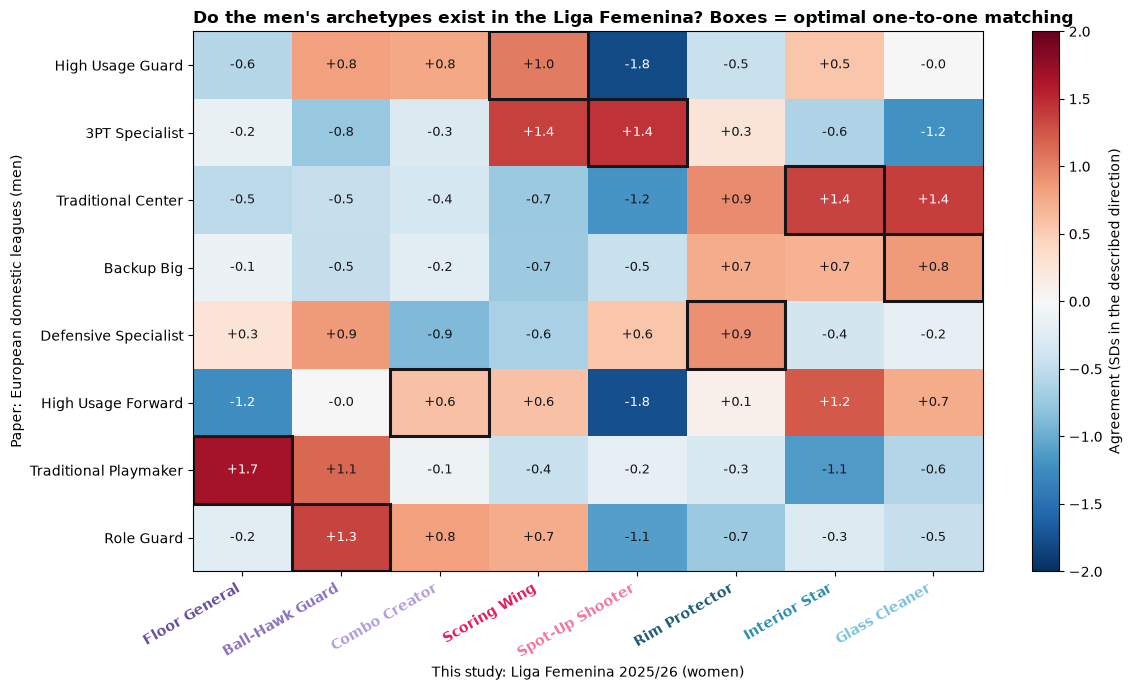

In [22]:
from scipy.optimize import linear_sum_assignment
import matplotlib.patches as patches

paper = {   # "Distinguishing Features" column of the paper's European AA table (Section 5.1)
    "High Usage Guard":      {"usg_pct": 1, "pts_100": 1, "ast_pct": 1},
    "3PT Specialist":        {"fg3_share": 1, "fg3_pct": 1, "ft_rate": -1},
    "Traditional Center":    {"height": 1, "oreb_pct": 1, "dreb_pct": 1, "blk_pct": 1, "ft_rate": 1, "fg3_share": -1},
    "Backup Big":            {"height": 1, "oreb_pct": 1, "dreb_pct": 1, "blk_pct": 1, "ft_rate": 1, "fg3_share": -1,
                              "usg_pct": -1, "fg2_pct": -1},
    "Defensive Specialist":  {"stl_pct": 1, "blk_pct": 1, "usg_pct": -1},
    "High Usage Forward":    {"height": 1, "usg_pct": 1, "pts_100": 1, "fga_100": 1, "fg3_share": -1},
    "Traditional Playmaker": {"height": -1, "ast_pct": 1, "tov_pct": 1, "pts_100": -1},
    "Role Guard":            {"height": -1, "usg_pct": 1},
}

S = pd.DataFrame(0.0, index=list(paper), columns=feature_cols)          # sign matrix: 8 paper archetypes × 15 features
for p, d in paper.items():
    for f, s in d.items():
        S.loc[p, f] = s

agree = (S @ prof_z[feature_cols].T).div(S.abs().sum(axis=1), axis=0)  # average sign × z over mentioned features
rows, cols = linear_sum_assignment(-agree.to_numpy())                   # best one-to-one matching

matches = pd.DataFrame({"paper": agree.index[rows], "ours": agree.columns[cols],
                        "agreement": agree.to_numpy()[rows, cols]}).sort_values("agreement", ascending=False)
print(matches.round(2).to_string(index=False))
print("\nBest match for each paper archetype (many-to-one allowed):")
print(pd.DataFrame({"best": agree.idxmax(axis=1), "score": agree.max(axis=1)}).round(2))

fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(agree, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(order)), labels=order, rotation=30, ha="right")
for t, a in zip(ax.get_xticklabels(), order):
    t.set_color(colors[a]); t.set_fontweight("bold")
ax.set_yticks(range(len(agree)), labels=agree.index)
for i in range(agree.shape[0]):
    for j in range(agree.shape[1]):
        v = agree.iloc[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 1.2 else "#16161a")
for r, c in zip(rows, cols):                                             # box around the optimal one-to-one matches
    ax.add_patch(patches.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor="#16161a", lw=2.2))
ax.set_xlabel("This study: Liga Femenina 2025/26 (women)")
ax.set_ylabel("Paper: European domestic leagues (men)")
fig.colorbar(im, ax=ax, label="Agreement (SDs in the described direction)")
ax.set_title("Do the men's archetypes exist in the Liga Femenina? Boxes = optimal one-to-one matching",
             loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/paper_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading the matrix.** The two strongest pairs are role archetypes: Traditional Playmaker ↔ Floor General (+1.66)
and 3PT Specialist ↔ Spot-Up Shooter (+1.44), which are also our two most stable archetypes. Our Interior Star agrees
with both the paper's Traditional Center (+1.4) and High Usage Forward (+1.2): in the Liga Femenina, the interior
scorer and the interior rebounder are the same player, whereas the men's model separates them (High Usage Forward is
pushed to a weak, forced match with Combo Creator, +0.6). The men's High Usage Guard spreads over three of our
archetypes (Scoring Wing +1.0, Ball-Hawk Guard +0.8, Combo Creator +0.8), and the 3PT Specialist agrees equally with
Spot-Up Shooter and Scoring Wing: shooting splits into off-ball and on-ball profiles. The Defensive Specialist has no
clean counterpart: defence splits by zone (Rim Protector at the rim, Ball-Hawk Guard on the perimeter, with the ball).
Role Guard ↔ Ball-Hawk Guard (+1.35) rests on only two descriptors and is tested for robustness below.

**Robustness of the matching.** The sign encoding is our choice, so we drop one descriptor at a time (34 variants)
and redo the matching. A pair kept in most variants is robust; a pair that changes is fragile.

In [23]:
base = dict(zip(agree.index[rows], agree.columns[cols]))
base_best = agree.idxmax(axis=1)
kept, kept_best = {p: [] for p in paper}, {p: [] for p in paper}

for p0, d0 in paper.items():
    for f0 in d0:                                                   # drop one descriptor at a time
        S2 = S.copy()
        S2.loc[p0, f0] = 0
        a2 = (S2 @ prof_z[feature_cols].T).div(S2.abs().sum(axis=1), axis=0)
        r2, c2 = linear_sum_assignment(-a2.to_numpy())
        m2 = dict(zip(a2.index[r2], a2.columns[c2]))
        for p in paper:
            kept[p].append(m2[p] == base[p])
            kept_best[p].append(a2.loc[p].idxmax() == base_best[p])

robust = pd.DataFrame({"descriptors": [len(paper[p]) for p in paper],
                       "one_to_one": [base[p] for p in paper],
                       "kept_%": [np.mean(kept[p]) * 100 for p in paper],
                       "best_match": [base_best[p] for p in paper],
                       "best_kept_%": [np.mean(kept_best[p]) * 100 for p in paper]}, index=list(paper))
robust.round(0)

,descriptors,one_to_one,kept_%,best_match,best_kept_%
High Usage Guard,3,Scoring Wing,88.0,Scoring Wing,97.0
3PT Specialist,3,Spot-Up Shooter,91.0,Spot-Up Shooter,94.0
Traditional Center,6,Interior Star,56.0,Glass Cleaner,91.0
Backup Big,8,Glass Cleaner,56.0,Glass Cleaner,91.0
Defensive Specialist,3,Rim Protector,56.0,Rim Protector,94.0
High Usage Forward,5,Combo Creator,53.0,Interior Star,100.0
Traditional Playmaker,4,Floor General,100.0,Floor General,100.0
Role Guard,2,Ball-Hawk Guard,65.0,Ball-Hawk Guard,97.0


**Robustness.** Dropping one descriptor at a time (34 variants), three one-to-one pairs are robust, all on the
perimeter: Traditional Playmaker ↔ Floor General (100%), 3PT Specialist ↔ Spot-Up Shooter (91%) and High Usage Guard
↔ Scoring Wing (88%). Interior pairs change in about half the variants (53–56%), but each paper archetype's best match
(many-to-one) is robust in every case (91–100%): the interior archetypes compete for the same players of ours.

**Final mapping.** Perimeter roles correspond closely. The interior is organised differently: both men's centre types
(Traditional Center, Backup Big) point to our Glass Cleaner; our Interior Star matches the men's High Usage Forward
(100%); our Rim Protector matches the men's low-usage Defensive Specialist (94%), so rim protection is a specialised
role rather than the classic centre's job. Combo Creator is the best match of no men's archetype: a candidate
archetype specific to the Liga Femenina. Role Guard ↔ Ball-Hawk Guard rests on only two descriptors and is treated as weak.

**Figure: intra-archetype variance, this study vs the paper.** Paper values are read from the labels of its
Figures 3 (European AA) and 4 (NBA ADA).

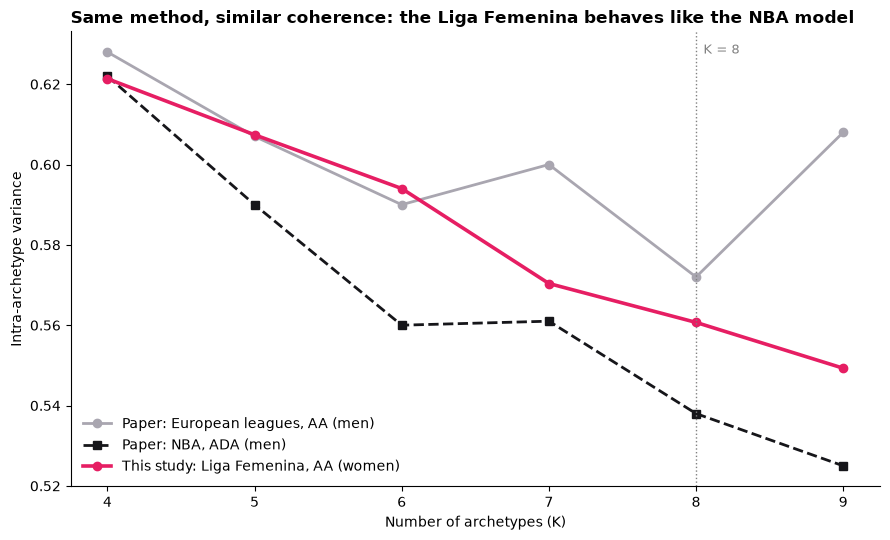

In [24]:
paper_euro = {4: 0.628, 5: 0.607, 6: 0.590, 7: 0.600, 8: 0.572, 9: 0.608}   # Figure 3, European AA (men)
paper_nba = {4: 0.622, 5: 0.590, 6: 0.560, 7: 0.561, 8: 0.538, 9: 0.525}    # Figure 4, NBA ADA (men)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(list(paper_euro), list(paper_euro.values()), marker="o", lw=2, color="#a9a6b0", label="Paper: European leagues, AA (men)")
ax.plot(list(paper_nba), list(paper_nba.values()), marker="s", lw=2, color="#16161a", ls="--", label="Paper: NBA, ADA (men)")
ax.plot(iv["k"], iv["intra_variance"], marker="o", lw=2.6, color="#e61e63", label="This study: Liga Femenina, AA (women)")
ax.axvline(8, color="grey", ls=":", lw=1)
ax.text(8.05, ax.get_ylim()[1] * 0.995, "K = 8", fontsize=9, color="grey", va="top")
ax.set_xlabel("Number of archetypes (K)")
ax.set_ylabel("Intra-archetype variance")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title("Same method, similar coherence: the Liga Femenina behaves like the NBA model", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/intra_variance_vs_paper.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading the figure.** All three curves lie in the same range (0.52–0.63): the same recipe yields archetypes of
similar coherence in women's and men's leagues. Up to K = 6 our curve is almost identical to the paper's European one
(0.621 vs 0.628, 0.607 vs 0.607, 0.594 vs 0.590): at a coarse level, the Liga Femenina is organised like the men's
European leagues. Beyond that, the European curve dips at K = 8 (the paper's reason for choosing it), while ours
decreases smoothly, with the shape of the paper's NBA curve. At K = 8 our value (0.561) lies between the two.
Caveats: the paper does not define its intra-archetype variance formula, so the comparison of levels is indicative;
and the NBA curve comes from Archetypoid Analysis, a related but different method. The version below corrects the title.

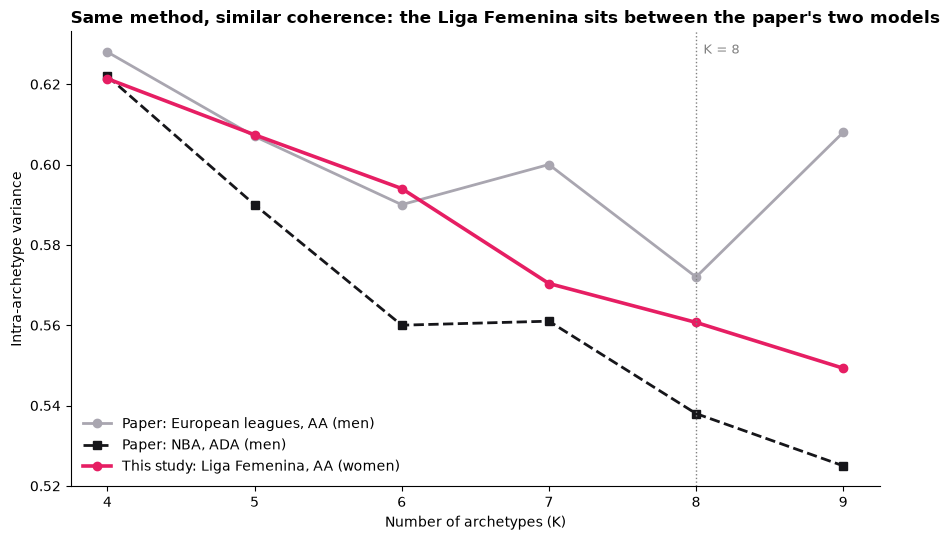

In [25]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(list(paper_euro), list(paper_euro.values()), marker="o", lw=2, color="#a9a6b0", label="Paper: European leagues, AA (men)")
ax.plot(list(paper_nba), list(paper_nba.values()), marker="s", lw=2, color="#16161a", ls="--", label="Paper: NBA, ADA (men)")
ax.plot(iv["k"], iv["intra_variance"], marker="o", lw=2.6, color="#e61e63", label="This study: Liga Femenina, AA (women)")
ax.axvline(8, color="grey", ls=":", lw=1)### 6.2 Archetypoids: the real player closest to each archetype
The paper's ADA model anchors each archetype to a real player. As an approximation, we find for each of our archetypes
the real player whose 15-feature profile is closest (Euclidean distance in z-scores) to the pure archetype, and compare
her with the purest player (highest weight). This is a proxy for ADA, which selects all archetypoids jointly.
ax.text(8.05, ax.get_ylim()[1] * 0.995, "K = 8", fontsize=9, color="grey", va="top")
ax.set_xlabel("Number of archetypes (K)")
ax.set_ylabel("Intra-archetype variance")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title("Same method, similar coherence: the Liga Femenina sits between the paper's two models",
             loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/intra_variance_vs_paper.png", dpi=200, bbox_inches="tight")
plt.show()

### 6.2 Archetypoids: the real player closest to each archetype
The paper's ADA model anchors each archetype to a real player. As an approximation, we find for each of our archetypes
the real player whose 15-feature profile is closest (Euclidean distance in z-scores) to the pure archetype, and compare
her with the purest player (highest weight). This is a proxy for ADA, which selects all archetypoids jointly.

In [26]:
Zp = zs[feature_cols].to_numpy()
A = prof_z.loc[order, feature_cols].to_numpy()
dist_all = np.sqrt(((Zp[:, None, :] - A[None, :, :]) ** 2).sum(axis=2))     # 142 players × 8 archetypes

rows_ = []
for k, a in enumerate(order):
    i = dist_all[:, k].argmin()                                               # closest real player
    j = mix25[a].idxmax()                                                     # purest player (highest weight)
    rows_.append({"archetype": a,
                  "closest_player": nice(mix25.loc[i, "player"]), "closest_team": mix25.loc[i, "team"].title(),
                  "distance": dist_all[i, k], "her_weight": mix25.loc[i, a],
                  "purest_player": nice(mix25.loc[j, "player"]), "purest_weight": mix25.loc[j, a]})
archetypoids = pd.DataFrame(rows_).set_index("archetype")

print(f"Typical distance from a player to her nearest archetype: {np.median(dist_all.min(axis=1)):.2f}")
archetypoids.round(2)

Typical distance from a player to her nearest archetype: 3.63


,closest_player,closest_team,distance,her_weight,purest_player,purest_weight
archetype,,,,,,
Floor General,Lucia Togores Carpintero,Innova-Tsn Leganes,1.09,0.99,Lucia Togores Carpintero,0.99
Ball-Hawk Guard,Claudia Soriano Perez,Perfumerias Avenida,0.24,1.00,Claudia Soriano Perez,1.00
Combo Creator,Nikola Dudasova,Innova-Tsn Leganes,0.30,0.98,Nikola Dudasova,0.98
Scoring Wing,Madison Elizabeth Conner,Ingeniería Ambiental Cab Estepona,0.00,1.00,Madison Elizabeth Conner,1.00
Spot-Up Shooter,Zoe Hernandez Ortiz,Durán Maquinaria Ensino,0.51,1.00,Zoe Hernandez Ortiz,1.00
Rim Protector,Billie Kim Massey,Hozono Global Jairis,2.15,0.72,Nia Coffey,0.97
Interior Star,Sika Kone,Ingeniería Ambiental Cab Estepona,1.41,0.85,Aminata Gueye,0.92
Glass Cleaner,Lauren-Jenee Nneka Ebo,Club Joventut Badalona,0.39,1.00,Lauren-Jenee Nneka Ebo,1.00


**Reading the archetypoids.** The typical distance from a player to her nearest archetype is 3.63, yet six of our eight
archetypes have a real player almost on top of them: Scoring Wing is Madison Conner (distance 0.00), Ball-Hawk Guard
Claudia Soriano (0.24), Combo Creator Nikola Dudasova (0.30), Glass Cleaner Lauren Ebo (0.39), Spot-Up Shooter Zoe
Hernández (0.51) and Floor General Lucía Togores (1.09); in each case the closest and the purest player coincide.
Archetypal Analysis seeks the extremes of the data, and in a league of 142 players these extremes are often individual
players: the archetypoid interpretability the paper obtains with ADA appears naturally here. The two interior archetypes
are synthetic: no real player is close to the pure Rim Protector (closest: Billie Massey, 2.15) or Interior Star
(Sika Koné, 1.41), and the closest and purest players differ. These are also the archetypes with fragile matches to the
paper. Caveat: an archetype anchored on one player depends on that player; refitting without the anchor player is
left as a robustness test.

### 6.3 Testing the paper's central claim: players are mixtures
The paper argues that players are blends of archetypes, citing main-archetype weights of 57% (Osetkowski), 53.5%
(Antetokounmpo) and 72% (Howard, "one of the highest concentrations"), against ~90% memberships typical of Gaussian
mixture models. We look at the distribution of the main-archetype weight in the Liga Femenina.

Median main-archetype weight: 47%
Players above 50%: 41%
Players above 72% (Howard): 12%
Players above 90% (GMM-like): 6%


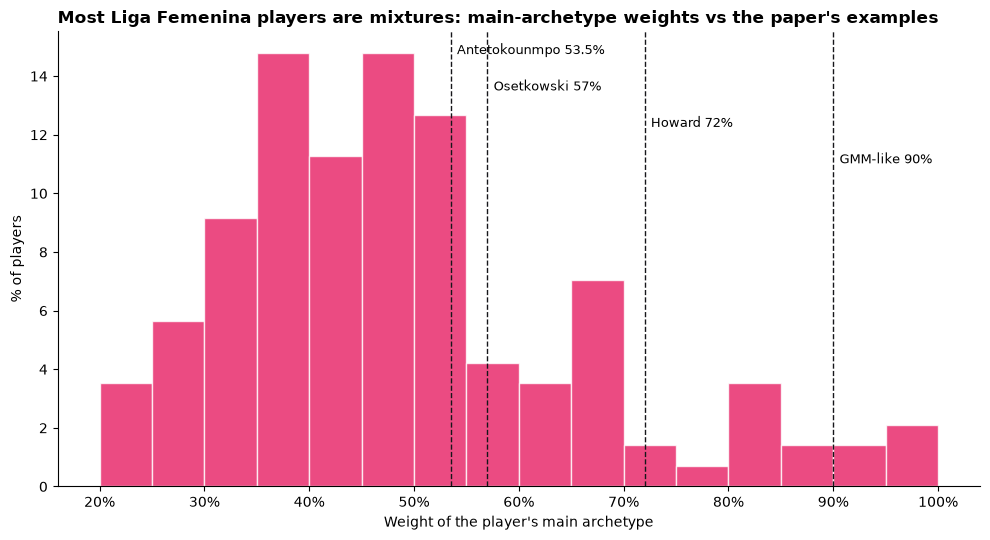

In [27]:
mw = mix25["main_weight"]
print(f"Median main-archetype weight: {mw.median():.0%}")
for t, name in [(0.5, "50%"), (0.72, "72% (Howard)"), (0.9, "90% (GMM-like)")]:
    print(f"Players above {name}: {(mw > t).mean():.0%}")

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.hist(mw, bins=np.arange(0.2, 1.05, 0.05), weights=np.ones(len(mw)) / len(mw) * 100,
        color="#e61e63", alpha=0.8, edgecolor="white")
refs = {"Antetokounmpo 53.5%": 0.535, "Osetkowski 57%": 0.57, "Howard 72%": 0.72, "GMM-like 90%": 0.90}
for k, (lbl, v) in enumerate(refs.items()):
    ax.axvline(v, color="#16161a", ls="--", lw=1)
    ax.text(v + 0.006, ax.get_ylim()[1] * (0.95 - 0.08 * k), lbl, fontsize=9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("Weight of the player's main archetype")
ax.set_ylabel("% of players")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Most Liga Femenina players are mixtures: main-archetype weights vs the paper's examples",
             loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/mixture_weights.png", dpi=200, bbox_inches="tight")
plt.show()

**Result.** The bulk of main-archetype weights lies between 35% and 55%: the typical Liga Femenina player has no
majority archetype, and is more mixed than the paper's own examples (Antetokounmpo 53.5%, Osetkowski 57%). Only 6% of
players exceed 90%, so Archetypal Analysis avoids the near-hard memberships the paper attributes to Gaussian mixtures.
12% exceed Howard's 72%, described as one of the highest EuroLeague concentrations; most of this right tail consists of
the players on whom archetypes are anchored (Section 6.2), an effect of a 142-player league. The paper reports
selected examples rather than full distributions, so this comparison is indicative.

### 6.4 Summary of the comparison with the paper

**What the Liga Femenina confirms**
- The method transfers: with the same recipe, archetypes are interpretable and of similar coherence (intra-archetype
  variance 0.55–0.62 vs 0.53–0.63 in the paper).
- Players are mixtures: the typical main-archetype weight is below 50%; only 6% exceed 90%.
- Role archetypes are shared across men's and women's basketball: Traditional Playmaker ↔ Floor General (robust in
  100% of variants) and 3PT Specialist ↔ Spot-Up Shooter (91%); High Usage Guard ↔ Scoring Wing (88%).

**What differs**
- The interior is organised differently: both men's centre types point to our Glass Cleaner, our Interior Star matches
  the men's High Usage Forward, and our Rim Protector matches the men's low-usage Defensive Specialist.
- Combo Creator has no men's counterpart: a candidate archetype specific to the Liga Femenina.
- No single diagnostic selects K = 8 here (as in the paper's NBA model); the choice rests on several criteria together.

**What this study adds**
- A women's league, testing the "any league" claim outside men's basketball.
- Stability of each archetype across 20 refits (role archetypes stable, high-usage archetypes not).
- A frozen-model projection to a new season with a noise baseline for early-season samples.
- Shrinkage of shooting percentages for small samples.
- Quantitative claims the paper makes qualitatively: positions do not capture roles; roles change between seasons.

**What the paper has and this study does not**
- Lineup-level analysis (on/off net ratings, the Howard case study) and Archetypoid Analysis proper: future work.
- An exact comparison would require the paper's numerical archetype profiles.